# The digits experiment
Recognize handwritten digits using the [scikit-learn 8×8 digits dataset](https://scikit-learn.org/stable/modules/generated/sklearn.datasets.load_digits.html) and Neuralplex's manual backpropagation.

Follow the [project setup instructions](README.md), then run the cells below.

Run cells in order. Restart the kernel and run all cells when changing model parameters; rerunning the training cell alone continues training. The final test set is for evaluation, not choosing hyperparameters. If you want to tune, first reserve a validation subset from the training data.


In [1]:
%matplotlib inline
from random import Random

import matplotlib.pyplot as plt
from IPython.display import display
from sklearn.datasets import load_digits
from sklearn.metrics import accuracy_score, confusion_matrix
from sklearn.model_selection import train_test_split

from neuralplex import Network, Layer, Neuron
from visualizations import plot_predictions, plot_confusion_matrix


## 1. Inspect the images
Each image has 64 pixels with intensities from 0 to 16. Look at examples before preparing the numerical inputs.


Images: (1797, 8, 8) Labels: (1797,)


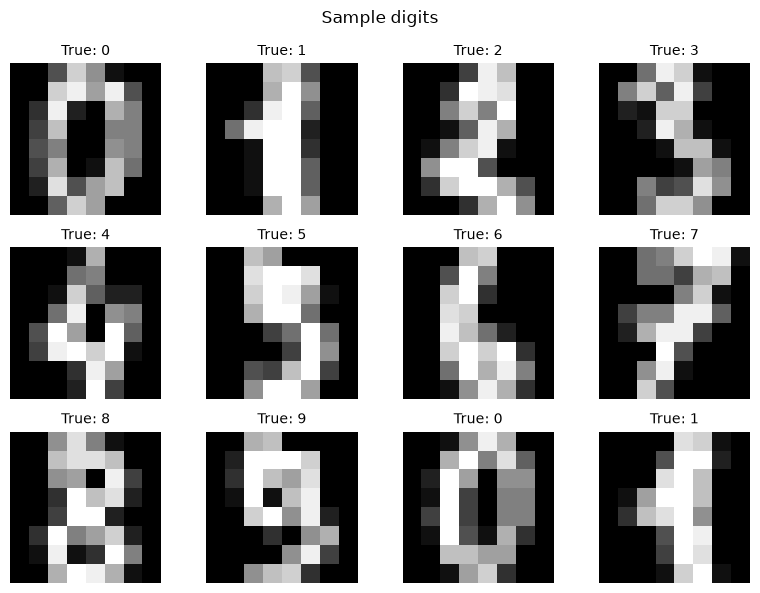

In [2]:
digits = load_digits()
print('Images:', digits.images.shape, 'Labels:', digits.target.shape)
samples_figure = plot_predictions(digits.images[:12], digits.target[:12])
display(samples_figure)
plt.close(samples_figure)


## 2. Normalize and split
Divide by the known maximum intensity, 16. This scaling does not learn anything from the test data. A stratified split preserves approximately the same class proportions in each set. Test images are never passed to `train`.


In [3]:
SEED = 42
STEP = 0.001
EPOCHS = 20

pixels = (digits.data / 16.0).tolist()
labels = digits.target.tolist()
train_indices, test_indices = train_test_split(
    list(range(len(labels))), test_size=0.25, random_state=SEED, stratify=labels
)
print(f'{len(train_indices)} training images; {len(test_indices)} test images')


1347 training images; 450 test images


## 3. Construct a 64 → 16 → 10 network
The hidden neurons use tanh so they can learn nonlinear features. The ten linear outputs correspond to digits 0 through 9. Their values are scores, not probabilities. We choose the largest score for the prediction.


In [4]:
network = Network([
    Layer([Neuron(name=f'i{i}') for i in range(64)]),
    Layer([Neuron(name=f'h{i}', activation='tanh') for i in range(16)], step=STEP),
    Layer([Neuron(name=f'digit-{i}') for i in range(10)], step=STEP),
], seed=SEED)
rng = Random(SEED)
print('Trainable parameters:', sum(len(n.weights) + 1
      for layer in network.layers[1:] for n in layer.neurons))


Trainable parameters: 1210


## 4. Train with one-hot targets
A label such as 3 becomes `[0, 0, 0, 1, 0, 0, 0, 0, 0, 0]`. Each update minimizes half the summed squared error of the ten scores. Shuffle the training order each epoch and track loss without looking at the test set.


In [5]:
training_losses = []
for epoch in range(EPOCHS):
    rng.shuffle(train_indices)
    loss = 0.0
    for index in train_indices:
        target = [float(digit == labels[index]) for digit in range(10)]
        network.train(pixels[index], target)
        # These cached values are from the forward pass before the update.
        loss += sum((neuron.value - expected)**2 / 2
                    for neuron, expected in zip(network.output_layer.neurons, target))
    training_losses.append(loss / len(train_indices))
    print(f'Epoch {epoch + 1:2d}/{EPOCHS}: training loss = {training_losses[-1]:.6f}')


Epoch  1/20: training loss = 0.449515


Epoch  2/20: training loss = 0.419132


Epoch  3/20: training loss = 0.397833


Epoch  4/20: training loss = 0.375105


Epoch  5/20: training loss = 0.352158


...

Epoch 16/20: training loss = 0.224820


Epoch 17/20: training loss = 0.219327


Epoch 18/20: training loss = 0.214327


Epoch 19/20: training loss = 0.210117


Epoch 20/20: training loss = 0.206096


## 5. Evaluate unseen images
Predict the test images only after training. Compare accuracy with a baseline that always predicts the most common training digit.


In [6]:
predictions = []
for index in test_indices:
    scores = network.predict(pixels[index])
    predictions.append(max(range(10), key=lambda digit: scores[digit]))
truth = [labels[index] for index in test_indices]
accuracy = accuracy_score(truth, predictions)
matrix = confusion_matrix(truth, predictions, labels=list(range(10)))
majority = max(range(10), key=lambda digit: sum(labels[i] == digit for i in train_indices))
baseline = sum(label == majority for label in truth) / len(truth)
report = (f'Train: {len(train_indices)}; test: {len(test_indices)}\n'
          f'Seed: {SEED}; epochs: {EPOCHS}; step: {STEP}\n'
          f'Test accuracy: {accuracy:.2%}\n'
          f'Training-majority baseline: {baseline:.2%}\n'
          f'Confusion matrix (rows=true, columns=predicted):\n{matrix}\n')
print(report)


Train: 1347; test: 450
Seed: 42; epochs: 20; step: 0.001
Test accuracy: 90.22%
Training-majority baseline: 10.22%
Confusion matrix (rows=true, columns=predicted):
[[44  0  0  0  1  0  0  0  0  0]
 [ 0 34  4  0  1  2  3  0  0  2]
 [ 0  0 44  0  0  0  0  0  0  0]
 [ 0  0  1 44  0  1  0  0  0  0]
 [ 0  2  0  0 41  0  0  2  0  0]
 [ 0  0  0  0  0 44  0  0  0  2]
 [ 0  1  0  0  0  0 43  0  1  0]
 [ 0  0  0  0  0  0  0 45  0  0]
 [ 0  6  2  3  0  3  1  1 26  1]
 [ 1  0  0  0  0  0  0  2  1 41]]



## 6. Inspect predictions and errors
These are the first twelve test images in split order. The confusion matrix includes all test images. Rows are true labels and columns are predictions.


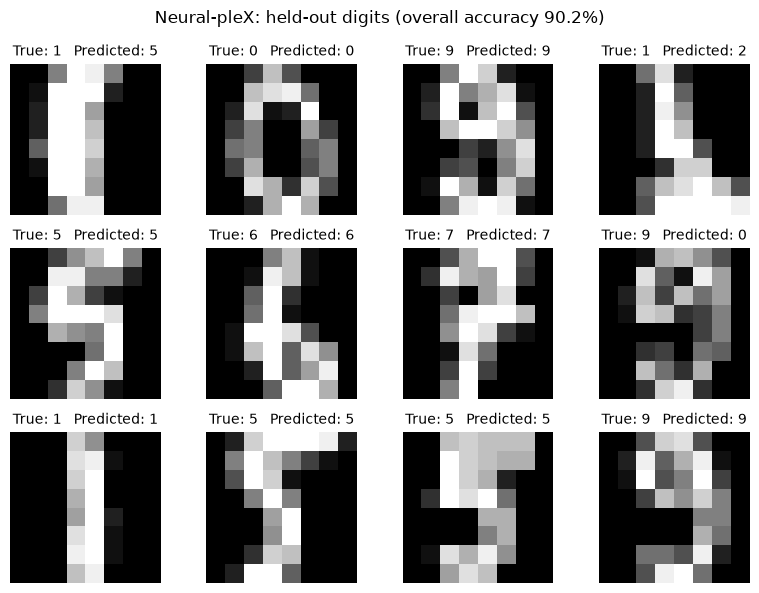

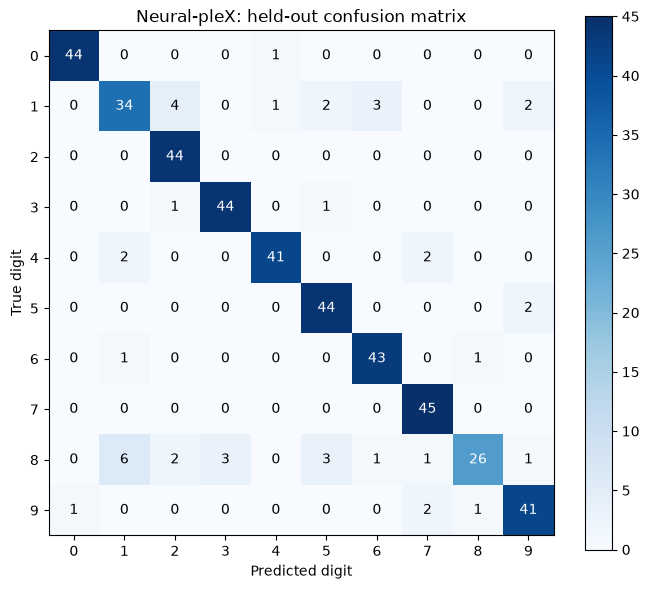

In [7]:
prediction_figure = plot_predictions(
    digits.images[test_indices[:12]], truth[:12], predictions[:12],
    title=f'Neural-pleX: held-out digits (overall accuracy {accuracy:.1%})'
)
display(prediction_figure)
plt.close(prediction_figure)
confusion_figure = plot_confusion_matrix(matrix)
display(confusion_figure)
plt.close(confusion_figure)


## 7. Explore one prediction
Change `test_position` to inspect another held-out image and its ten scores.


True digit: 1
Predicted digit: 5
0: 0.0403
1: 0.2086
2: 0.0438
3: -0.1238
4: 0.1988
5: 0.3226
6: 0.1920
7: 0.0342
8: 0.2394
9: -0.1583


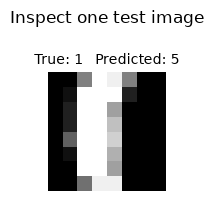

In [8]:
test_position = 0
index = test_indices[test_position]
scores = network.predict(pixels[index])
print('True digit:', labels[index])
print('Predicted digit:', max(range(10), key=lambda digit: scores[digit]))
for digit, score in enumerate(scores):
    print(f'{digit}: {score:.4f}')
inspection_figure = plot_predictions(digits.images[[index]], [labels[index]],
                                    [max(range(10), key=lambda digit: scores[digit])],
                                    title='Inspect one test image')
display(inspection_figure)
plt.close(inspection_figure)
